**Task 6: Feature Selection**

In [1]:
# Import libraries used across the notebook
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from imblearn.over_sampling import SMOTE

In [2]:
# Load dataset
df_clean = pd.read_csv('C:\\Users\\User\\Desktop\\PG230\\PG230_Bank_Loan_default_prediction\\results\\outputs\\new_featured_data.csv')

In [3]:
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel
from sklearn.feature_selection import VarianceThreshold

In [4]:
# Seperate features and the target variable
X = df_clean.drop('loan_status', axis=1)
y = df_clean['loan_status']

In [5]:
print("Original shape:", df_clean.shape)
print(df_clean)

Original shape: (36082, 27)
       person_age  person_gender  person_income  person_emp_exp  loan_amnt  \
0       -1.397814              0      -1.828331       -1.050160  -1.521430   
1       -1.397814              0      -1.807177       -1.050160  -1.207890   
2       -1.397814              0      -1.813881       -1.050160  -1.396014   
3       -0.622076              0      -1.765060       -0.792289  -1.364660   
4       -0.622076              0      -1.778245       -1.050160  -1.416916   
...           ...            ...            ...             ...        ...   
36077    1.187981              1       2.109884        1.270682   0.844542   
36078    0.153663              0      -1.093809       -0.018675  -0.685323   
36079    0.153663              1      -0.699861        0.497068   1.404943   
36080    1.705140              1      -0.416202        0.754939  -1.151244   
36081   -0.622076              1      -0.584829       -0.792289  -0.337294   

       loan_int_rate  loan_percent_

**Select method 1: Variance Threshold**

In [6]:
# Apply Variance Threshold
var_thresh = VarianceThreshold(threshold=0.01)  # threshold=0 means drop only constant cols
X_var_selected = var_thresh.fit_transform(X)
kept_after_var = X.columns[var_thresh.get_support()]

print("Features kept after Variance Threshold:", kept_after_var.tolist())

# Identify dropped ones
dropped_by_var = [col for col in X.columns if col not in kept_after_var]
print("Features dropped by Variance Threshold:", dropped_by_var)

Features kept after Variance Threshold: ['person_age', 'person_gender', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score', 'previous_loan_defaults_on_file', 'person_education_Bachelor', 'person_education_Doctorate', 'person_education_High School', 'person_education_Master', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE', 'debt_to_income_ratio']
Features dropped by Variance Threshold: ['person_home_ownership_OTHER', 'age_group_Adult', 'age_group_Senior', 'age_group_Elder']


In [7]:
#  dataframe after dropping low variance features
X_var_df = pd.DataFrame(X_var_selected, columns=kept_after_var)
print("Shape after VarianceThreshold:", X_var_df.shape)
print(X_var_df)

Shape after VarianceThreshold: (36082, 22)
       person_age  person_gender  person_income  person_emp_exp  loan_amnt  \
0       -1.397814            0.0      -1.828331       -1.050160  -1.521430   
1       -1.397814            0.0      -1.807177       -1.050160  -1.207890   
2       -1.397814            0.0      -1.813881       -1.050160  -1.396014   
3       -0.622076            0.0      -1.765060       -0.792289  -1.364660   
4       -0.622076            0.0      -1.778245       -1.050160  -1.416916   
...           ...            ...            ...             ...        ...   
36077    1.187981            1.0       2.109884        1.270682   0.844542   
36078    0.153663            0.0      -1.093809       -0.018675  -0.685323   
36079    0.153663            1.0      -0.699861        0.497068   1.404943   
36080    1.705140            1.0      -0.416202        0.754939  -1.151244   
36081   -0.622076            1.0      -0.584829       -0.792289  -0.337294   

       loan_int_rate

**Select method 2: Random Forest**

* We used a barplot to visualize the feature importance base on Random forest.


Features selected by Random Forest:
 Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score', 'previous_loan_defaults_on_file',
       'person_home_ownership_OWN', 'person_home_ownership_RENT',
       'loan_intent_HOMEIMPROVEMENT', 'debt_to_income_ratio'],
      dtype='object')


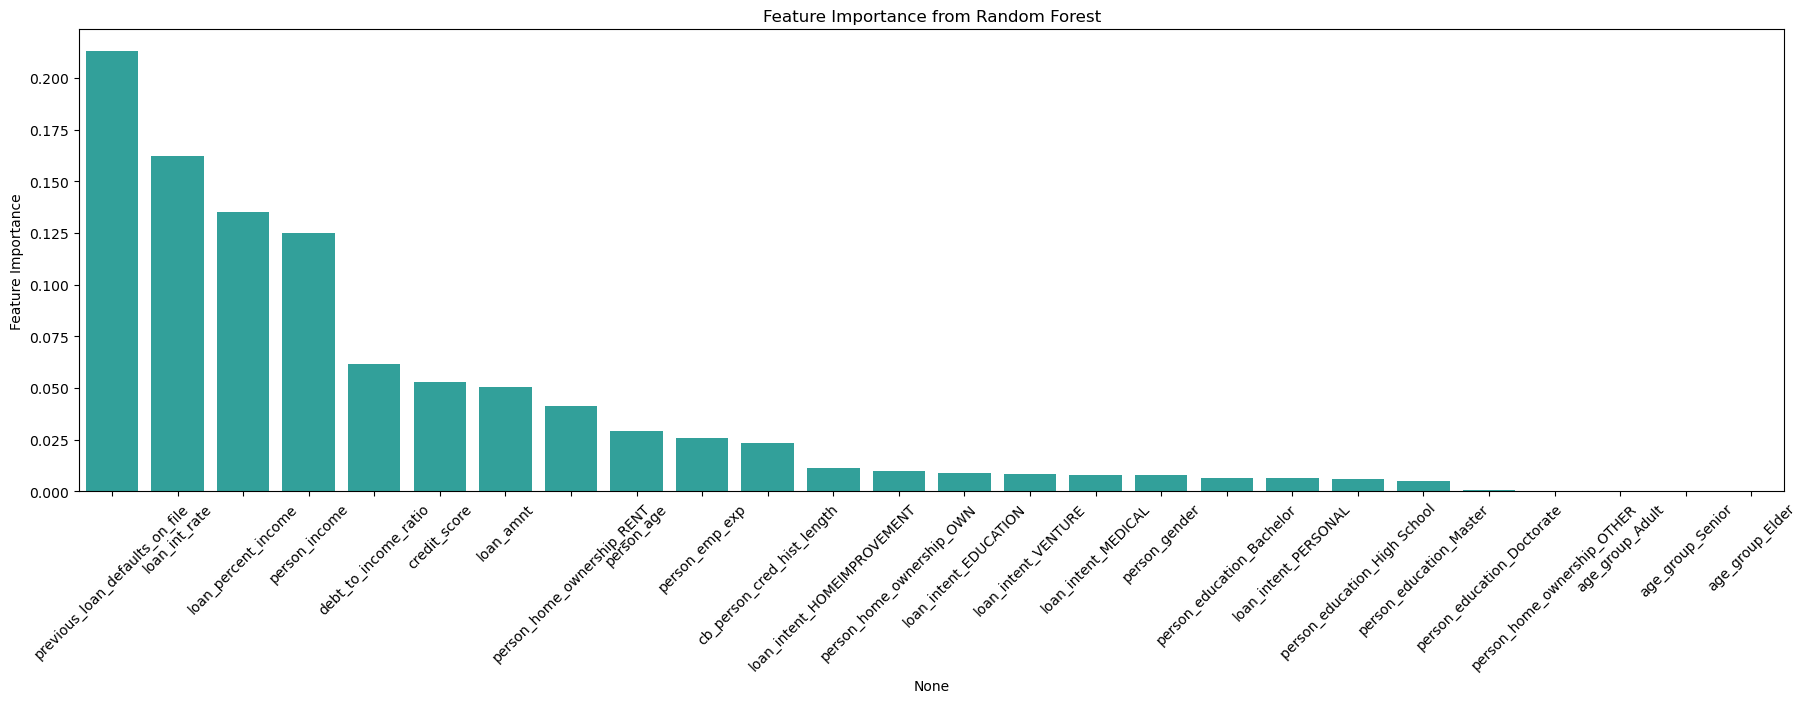

In [8]:
# Model-Based Feature Selection with Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X, y)

model_selector = SelectFromModel(rf, prefit=True, threshold='median')
selected_features = X.columns[model_selector.get_support()]
print("Features selected by Random Forest:\n", selected_features)

importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(22,6))
sns.barplot(x=importances.index, y=importances.values, color="lightseagreen")
plt.xticks(rotation=45)
plt.ylabel("Feature Importance")
plt.title("Feature Importance from Random Forest")
plt.show()

In [9]:
# Train Random Forest on variance-thresholded features
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_var_df, y)

# Select features above median importance
model_selector = SelectFromModel(rf, prefit=True, threshold='median')
selected_features = X_var_df.columns[model_selector.get_support()]
print("Features selected by Random Forest:\n", selected_features)

Features selected by Random Forest:
 Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score', 'previous_loan_defaults_on_file',
       'person_home_ownership_RENT', 'debt_to_income_ratio'],
      dtype='object')


In [10]:
# Create dataset with only selected features
X_final = selected_features.copy()
print(X_final)

Index(['person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
       'credit_score', 'previous_loan_defaults_on_file',
       'person_home_ownership_RENT', 'debt_to_income_ratio'],
      dtype='object')


**Final output after feature selection**

In [11]:
# Create dataset with only selected features
X_final_df = X_var_df[X_final]

df_final = X_final_df.copy()
df_final['Loan_Status'] = y.values  # add target


In [12]:
print(df_final)

       person_age  person_income  person_emp_exp  loan_amnt  loan_int_rate  \
0       -1.397814      -1.828331       -1.050160  -1.521430       0.088373   
1       -1.397814      -1.807177       -1.050160  -1.207890      -1.277767   
2       -1.397814      -1.813881       -1.050160  -1.396014       1.317900   
3       -0.622076      -1.765060       -0.792289  -1.364660       0.037143   
4       -0.622076      -1.778245       -1.050160  -1.416916      -1.226537   
...           ...            ...             ...        ...            ...   
36077    1.187981       2.109884        1.270682   0.844542       2.062446   
36078    0.153663      -1.093809       -0.018675  -0.685323       1.690173   
36079    0.153663      -0.699861        0.497068   1.404943       1.632112   
36080    1.705140      -0.416202        0.754939  -1.151244      -0.294146   
36081   -0.622076      -0.584829       -0.792289  -0.337294       2.106846   

       loan_percent_income  cb_person_cred_hist_length  credit_

After feature selection we were able to reduct the number of columns to 12 from 27 (27 was after encoding and feature engineering originally it was just 14 columns)

In [13]:
df_final.to_csv('C:\\Users\\User\\Desktop\\PG230\\PG230_Bank_Loan_default_prediction\\results\\outputs\\final_result.csv', index=False)